# Why SymPy Quantum Calculations Take Too Long, and How to Fix Them

Symbolic quantum calculations feel fine for one or two qubits, then suddenly take minutes. This
notebook **measures** why instead of guessing, then tests the fixes. It also covers checking
quantum formulas for units, and reversible logic, the classical backbone of quantum circuits.

| § | question | answer, measured |
|---|---|---|
| 1 | why does it blow up? | $2^n$-sized objects, a full $2^n\times2^n$ matrix, and expressions that grow |
| 2 | fix 1: never build the full matrix | apply gates to the **state** |
| 3 | fixes 2–4: `lambdify`, `cse`, targeted simplification | numbers out fast, less repeated work |
| 4 | when to stop using symbols | NumPy past ~10 qubits |
| 5 | units: is $\Omega_\text{Rabi} = dE/\hbar$ a frequency? | dimension vectors |
| 6 | logic: CNOT, Toffoli, NAND, `satisfiable` | Boolean algebra = permutation matrices |

Module: [`dgs/sympy_qis_performance.py`](../dgs/sympy_qis_performance.py)

In [1]:
import sys, pathlib, time
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import sympy as sp
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Math
sp.init_printing()
from dgs.sympy_qis_performance import (
    a, b, c, circuit_full_state, circuit_state_vector, numeric_state, purity_expression, cse_savings,
    expression_size, time_call, check_qis_units, gates_within_coherence, cnot_logic, toffoli_logic,
    logic_to_permutation, toffoli_is_nand, inputs_for_toffoli_output,
)
TH = sp.symbols("t0:12", real=True)

# 1. Where the time goes

The test circuit: an $R_y(\theta_k)$ rotation on every qubit, then a chain of CNOTs. That's a typical
entangling layer, written with **symbolic** angles. The naive approach builds the whole
$2^n\times 2^n$ unitary with Kronecker products, then multiplies it onto $|0\cdots0\rangle$.

,qubits,dimension 2^n,full-matrix (s),state-vector (s),speed-up,expression size (ops)
0,2,4,0.00562,0.00015,37.62584,20
1,3,8,0.00844,0.00030,28.06017,64
2,4,16,0.03435,0.00067,51.10861,176
3,5,32,0.24983,0.00235,106.41004,448
4,6,64,1.63987,0.00885,185.36695,1088


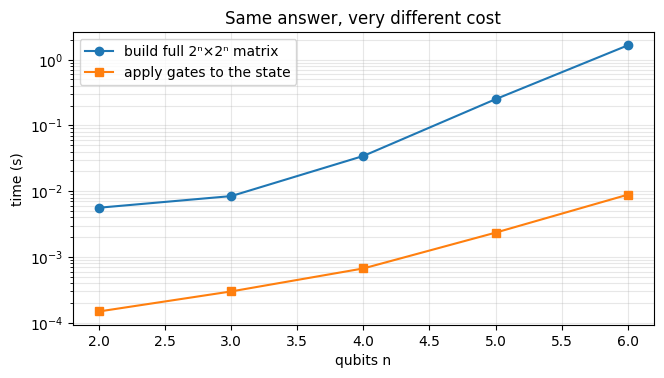

In [2]:
rows = []
for n in (2, 3, 4, 5, 6):
    tf, Sf = time_call(circuit_full_state, n, TH)
    tv, Sv = time_call(circuit_state_vector, n, TH)
    rows.append({"qubits": n, "dimension 2^n": 2**n, "full-matrix (s)": tf, "state-vector (s)": tv,
                 "speed-up": tf/tv, "expression size (ops)": expression_size(Sv)})
df = pd.DataFrame(rows); display(df.round(5))
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.semilogy(df["qubits"], df["full-matrix (s)"], "o-", label="build full 2ⁿ×2ⁿ matrix")
ax.semilogy(df["qubits"], df["state-vector (s)"], "s-", label="apply gates to the state")
ax.set(xlabel="qubits n", ylabel="time (s)", title="Same answer, very different cost"); ax.legend(); ax.grid(alpha=0.3, which="both"); plt.show()

Two separate things blow up:

1. **Object size.** A state has $2^n$ amplitudes, but the full unitary has $4^n$ entries, and multiplying
   two of them costs $\sim 8^n$ operations. Every operation is *symbolic*: SymPy builds expression trees
   instead of multiplying numbers.
2. **Expression size.** Each amplitude is a product of $n$ sines and cosines, so the total "ops" grows
   with $n\,2^n$, and anything that walks the expressions (`simplify`, `subs`, printing) pays for all of it.

# 2. Fix 1: never build the full matrix

Single-qubit rotations on $|0\rangle$ give a **product state** (just multiply amplitudes), and a CNOT only
**swaps pairs of amplitudes** (a permutation of indices). No $2^n\times2^n$ matrix is ever formed. The
check that it gives the same answer is numeric (lambdify both), since a symbolic `simplify` check is
itself the slow thing being avoided:

In [3]:
vals = np.linspace(0.3, 1.1, 12)
for n in (3, 4, 5):
    f_full = sp.lambdify(TH[:n], circuit_full_state(n, TH), "numpy")
    f_vec = sp.lambdify(TH[:n], circuit_state_vector(n, TH), "numpy")
    d = np.max(np.abs(np.array(f_full(*vals[:n]), float).ravel() - np.array(f_vec(*vals[:n]), float).ravel()))
    print(f"n = {n}: max |full − state-vector| = {d:.1e}")

n = 3: max |full − state-vector| = 0.0e+00
n = 4: max |full − state-vector| = 0.0e+00


n = 5: max |full − state-vector| = 0.0e+00


# 3. Fixes 2–4: lambdify, cse, targeted simplification

- **`lambdify`**: once the *formula* is symbolic, turn it into a NumPy function and evaluate it on
  thousands of parameter values. Don't call `subs` in a loop.
- **`cse`**: common-subexpression elimination. The same $\cos(\theta_k/2)$ factors appear
  everywhere, so compute each one once.
- **Targeted simplification**: `simplify()` tries *everything*. If you know the expression is
  trigonometric, `trigsimp` is usually faster.

In [4]:
e = purity_expression(4, TH)
before, after = cse_savings(e)
print(f"Σ|ψ_k|⁴ for 4 qubits: {before} operations → {after} after cse  ({before/after:.1f}× less work)")
t0 = time.perf_counter(); sp.simplify(e); t_simp = time.perf_counter() - t0
t0 = time.perf_counter(); sp.trigsimp(e); t_trig = time.perf_counter() - t0
print(f"simplify(): {t_simp:.2f} s    trigsimp(): {t_trig:.2f} s")
f = sp.lambdify(TH[:4], e, "numpy")
grid = np.random.default_rng(0).uniform(0, np.pi, (100_000, 4))
t0 = time.perf_counter(); vals_ = f(*grid.T); t_lam = time.perf_counter() - t0
t0 = time.perf_counter(); [e.subs(dict(zip(TH[:4], row))) for row in grid[:200]]; t_subs = (time.perf_counter() - t0) / 200 * 100_000
print(f"evaluate at 100,000 parameter points: lambdify {t_lam*1e3:.1f} ms   vs   subs() loop ≈ {t_subs:.0f} s (extrapolated from 200)")

Σ|ψ_k|⁴ for 4 qubits: 255 operations → 61 after cse  (4.2× less work)


simplify(): 1.24 s    trigsimp(): 0.63 s


evaluate at 100,000 parameter points: lambdify 153.1 ms   vs   subs() loop ≈ 1231 s (extrapolated from 200)


# 4. When to stop using symbols

Symbolic math is for **insight on small systems**: exact formulas, limits, structure. For scale, use
numbers. The same circuit in NumPy, state-vector style:

In [5]:
for n in (10, 16, 20, 22):
    t, psi = time_call(numeric_state, n, np.linspace(0.1, 1.5, n))
    print(f"n = {n:2d}: {2**n:>9,d} amplitudes in {t*1e3:7.1f} ms   (norm = {np.linalg.norm(psi):.6f}, memory ≈ {psi.nbytes/1e6:.0f} MB)")

n = 10:     1,024 amplitudes in     0.3 ms   (norm = 1.000000, memory ≈ 0 MB)
n = 16:    65,536 amplitudes in     3.9 ms   (norm = 1.000000, memory ≈ 1 MB)


n = 20: 1,048,576 amplitudes in   286.5 ms   (norm = 1.000000, memory ≈ 8 MB)


n = 22: 4,194,304 amplitudes in  1325.9 ms   (norm = 1.000000, memory ≈ 34 MB)


Each extra qubit doubles the memory, so ~30 qubits needs ~8 GB even in NumPy. That's why
dedicated simulators (and actual quantum hardware) exist. The rule of thumb: symbols up to a few
qubits, NumPy up to ~25, specialized tools beyond.

# 5. Units: checking quantum formulas

Every term in a physics formula must have consistent dimensions. That's a free bug-catcher. Using
the repo's exact dimension vectors (`dgs.units_dimensions`):

In [6]:
for k, v in check_qis_units().items():
    print(f"[{k}] = {v}")
print(f"\nT2 = 100 µs, gate time = 50 ns → {gates_within_coherence(100e-6, 50e-9):.0f} gates before decoherence (a pure number)")
from sympy.physics.units import hbar, joule, electronvolt, convert_to, second, giga, hertz
E = convert_to(hbar * 2*sp.pi * 5e9*hertz, electronvolt)      # write 5e9 Hz: SymPy keeps unit PREFIXES (giga) as unevaluated factors
E_ueV = float(E / electronvolt) * 1e6
print(f"a 5 GHz superconducting qubit: ħω = {E_ueV:.1f} µeV, far below room-temperature kT ≈ 25,000 µeV → needs a dilution fridge (~10 mK, kT ≈ 0.9 µeV)")

[hbar*omega] = M L^2 T^-2
[Rabi d*E/hbar] = T^-1
[Omega*t] = 1

T2 = 100 µs, gate time = 50 ns → 2000 gates before decoherence (a pure number)
a 5 GHz superconducting qubit: ħω = 20.7 µeV, far below room-temperature kT ≈ 25,000 µeV → needs a dilution fridge (~10 mK, kT ≈ 0.9 µeV)


$\Omega_\text{Rabi}t$ coming out **dimensionless** is the check that it's a rotation angle, so a
"π pulse" makes sense. And comparing $\hbar\omega$ to $kT$ explains why superconducting qubits have to
sit at millikelvin temperatures.

# 6. Logic: reversible gates

Classical gates like AND throw information away (two inputs, one output), but quantum gates must be
**reversible**. CNOT and Toffoli are reversible classical gates: written as Boolean algebra they're
XOR/AND expressions, and written as matrices they're **permutation matrices**, which are unitary.

In [7]:
display(Math(r"\text{CNOT}: (a,b) \mapsto " + sp.latex(cnot_logic())))
display(Math(r"\text{Toffoli}: (a,b,c) \mapsto " + sp.latex(toffoli_logic())))
print("CNOT as a permutation matrix:"); print(logic_to_permutation(cnot_logic(), (a, b)))
T = logic_to_permutation(toffoli_logic(), (a, b, c))
print("Toffoli is its own inverse (T·T = I):", bool(np.array_equal(T @ T, np.eye(8, dtype=int))))
print("Toffoli with c = 1 equals NAND(a, b):", toffoli_is_nand(), " → reversible logic is universal")
print("satisfiable(): inputs (a,b,c) that make the Toffoli target 1:", inputs_for_toffoli_output(True))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

CNOT as a permutation matrix:
[[1 0 0 0]
 [0 1 0 0]
 [0 0 0 1]
 [0 0 1 0]]
Toffoli is its own inverse (T·T = I): True
Toffoli with c = 1 equals NAND(a, b): True  → reversible logic is universal
satisfiable(): inputs (a,b,c) that make the Toffoli target 1: [(0, 0, 1), (0, 1, 1), (1, 0, 1), (1, 1, 0)]


Since NAND is universal, *any* classical computation can be done reversibly with Toffolis. That's
why quantum computers can run classical subroutines (like the modular arithmetic in Shor's algorithm)
without breaking unitarity.

## Exercises
1. Extend the circuit to `n = 7` with the full-matrix method only if you dare. Predict the time from the table first.
2. Write `apply_single_qubit(psi, U, k, n)` that applies a 2×2 gate to qubit `k` of a state vector, without Kronecker products.
3. Check the dimensions of the Schrödinger equation $i\hbar\,\partial_t\psi = H\psi$ with `check_homogeneous`.
4. Use `satisfiable` to find every input to a Fredkin (controlled-SWAP) gate whose first output is 1.